
# Transformer Model Comparison — LLM-as-a-Judge

This notebook analyses the performance of three Hugging Face transformer models:

- FLAN-T5 Small
- FLAN-T5 Base
- BlenderBot 400M Distill

The models are compared using:
1. Response generation time
2. Generated token counts
3. Response quality assessed by an OpenAI LLM judge

The objective is to investigate the trade-off between model efficiency and response quality.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the LLM evaluation results
results_path = Path("results/llm_evaluation.csv")

df = pd.read_csv(results_path)

# Display the first few rows
display(df.head())


,Model,Prompt,Response,Response Time (s),Generated Tokens,Accuracy,Relevance,Completeness,Judge Reasoning,Judge Model,Quality Score
0,google/flan-t5-small,Define artificial intelligence in one simple s...,Artificial intelligence,0.042,4,1,5,1,The response is relevant as it pertains to the...,gpt-4o-mini,7
1,google/flan-t5-small,Explain machine learning to a beginner in one ...,A machine learning machine is a machine that i...,0.150,18,0,1,1,The response is factually incorrect as it does...,gpt-4o-mini,2
2,google/flan-t5-small,Answer this geography question: What is the ca...,london,0.049,6,0,5,0,The response is factually incorrect as the cap...,gpt-4o-mini,5
3,google/flan-t5-base,Define artificial intelligence in one simple s...,Artificial intelligence is a type of artificia...,0.281,12,1,5,1,The response is factually incorrect as it defi...,gpt-4o-mini,7
4,google/flan-t5-base,Explain machine learning to a beginner in one ...,Machine learning is a process that uses data t...,0.388,18,3,5,4,The response is relevant and addresses the pro...,gpt-4o-mini,12


In [2]:
print(f"Number of evaluated responses: {len(df)}")
print(f"Number of models: {df['Model'].nunique()}")
print(f"Number of prompts: {df['Prompt'].nunique()}")

Number of evaluated responses: 9
Number of models: 3
Number of prompts: 3



## 1. Model Response Quality

This section compares the average response quality of the three models using scores assigned by the OpenAI LLM judge.

Each response is evaluated on three criteria:
- Accuracy (0–5)
- Relevance (0–5)
- Completeness (0–5)

The maximum combined quality score is 15.


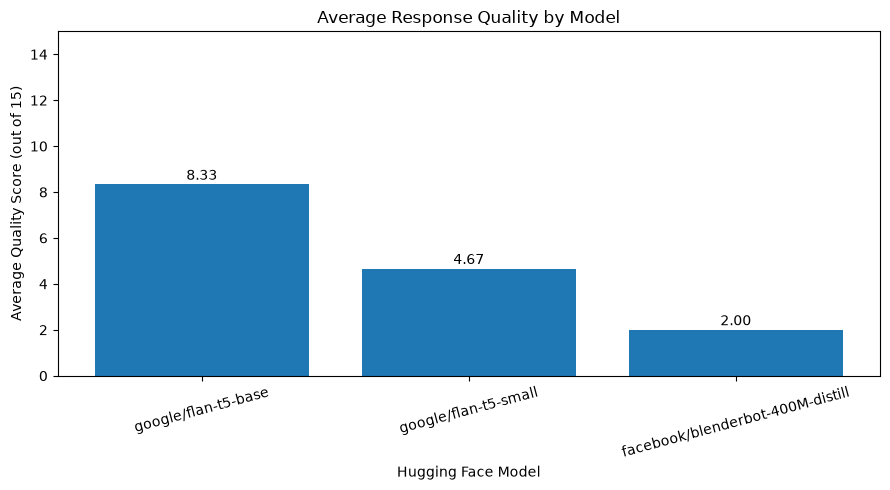

In [3]:

# Calculate average quality score for each model
quality_summary = (
    df.groupby("Model")["Quality Score"]
    .mean()
    .sort_values(ascending=False)
)

# Create bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    quality_summary.index,
    quality_summary.values
)

plt.title("Average Response Quality by Model")
plt.ylabel("Average Quality Score (out of 15)")
plt.xlabel("Hugging Face Model")
plt.ylim(0, 15)

# Display scores above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        f"{height:.2f}",
        ha="center"
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



## 2. Model Inference Performance

This section compares the average response generation time of the three transformer models.

Inference time is measured in seconds, excluding model loading and input tokenization.

Lower response times indicate faster generation, although differences in output length can affect performance.

The results are based on three prompts per model and should be treated as exploratory measurements rather than rigorous benchmarks.


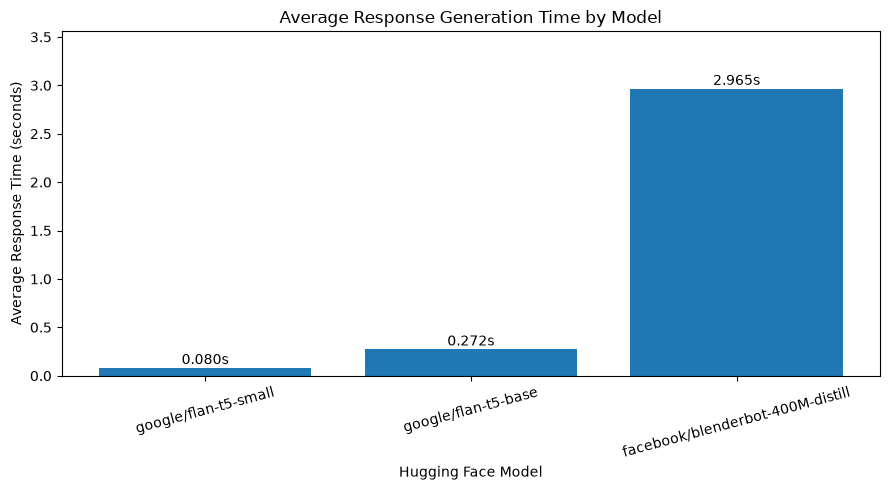

In [4]:

# Calculate average response generation time for each model
speed_summary = (
    df.groupby("Model")["Response Time (s)"]
    .mean()
    .sort_values()
)

# Create bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    speed_summary.index,
    speed_summary.values
)

plt.title("Average Response Generation Time by Model")
plt.xlabel("Hugging Face Model")
plt.ylabel("Average Response Time (seconds)")

# Display timings above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.04,
        f"{height:.3f}s",
        ha="center"
    )

plt.ylim(0, speed_summary.max() * 1.2)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



## 3. Response Quality vs. Inference Time

This analysis investigates the relationship between response quality and inference speed.

- **X-axis:** Average response generation time (seconds)
- **Y-axis:** Average quality score assigned by the LLM judge (0–15)

Ideally, a model would achieve high response quality with low inference time.

This comparison helps illustrate the trade-offs involved in selecting language models for practical applications.


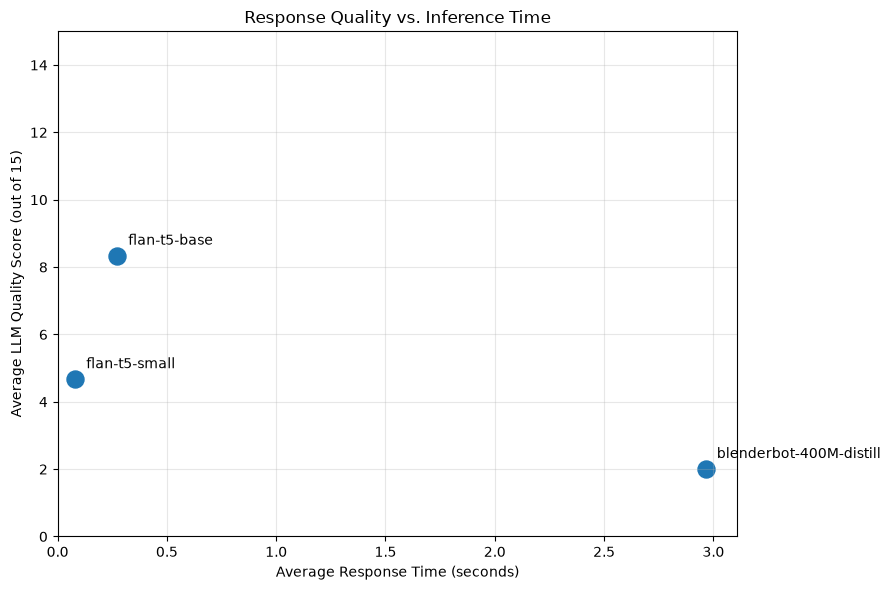

In [5]:

# Calculate average quality and response time for each model
performance_summary = (
    df.groupby("Model")
    .agg(
        Average_Quality=("Quality Score", "mean"),
        Average_Time=("Response Time (s)", "mean")
    )
    .reset_index()
)

# Create scatter plot
plt.figure(figsize=(9, 6))

plt.scatter(
    performance_summary["Average_Time"],
    performance_summary["Average_Quality"],
    s=150
)

# Label each model
for _, row in performance_summary.iterrows():
    plt.annotate(
        row["Model"].split("/")[-1],
        (row["Average_Time"], row["Average_Quality"]),
        xytext=(8, 8),
        textcoords="offset points"
    )

plt.title("Response Quality vs. Inference Time")
plt.xlabel("Average Response Time (seconds)")
plt.ylabel("Average LLM Quality Score (out of 15)")

plt.ylim(0, 15)
plt.xlim(left=0)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## 4. Key Findings

Three pretrained Hugging Face transformer models were evaluated using identical prompts and an OpenAI LLM-as-a-Judge.

### Response Quality

- **FLAN-T5 Base** achieved the highest average LLM-judged quality score (8.33/15).
- **FLAN-T5 Small** achieved a lower average quality score (4.67/15), frequently producing incomplete or incorrect responses.
- **BlenderBot 400M Distill** achieved the lowest average score (2.00/15), often producing conversational responses rather than directly following instructions.

### Inference Performance

- FLAN-T5 Small demonstrated the fastest average response generation time (0.080 seconds).
- FLAN-T5 Base provided a balance between response quality and generation speed (0.272 seconds).
- BlenderBot had the highest average response time (2.965 seconds).

### Quality vs. Speed

For the selected prompts, FLAN-T5 Base offered the most favourable balance between response quality and inference time.

However, the results are specific to the selected models, prompts, hardware and evaluation procedure.

## 5. Limitations

This experiment has several important limitations:

1. **Small evaluation dataset:** Only three prompts were tested per model.
2. **LLM judge bias:** The evaluation scores reflect the judgement of a single LLM and may contain inaccuracies or inconsistencies.
3. **Limited benchmark reliability:** Generation times were measured only once per prompt and may be influenced by hardware, output length and system activity.
4. **Task differences:** BlenderBot is optimised for conversational dialogue, whereas FLAN-T5 models are instruction-tuned. The selected prompts may therefore favour FLAN-T5.
5. **No independent ground truth:** The judge was not supplied with verified reference answers for factual questions.

## 6. Conclusion

This project demonstrates a reproducible workflow for comparing pretrained transformer language models.

It combines Hugging Face model inference, performance measurement, automated LLM-based evaluation and exploratory data analysis.

The experiment highlights that model size, generation speed and response quality are distinct characteristics, and that model selection should depend on the intended application.

Future improvements could include a larger evaluation dataset, multiple judge runs, reference-based factual evaluation and more rigorous inference benchmarking.
